### Step 2: Feynman–Kac, solving a PDE with Monte Carlo (weeks 1–2)

Consider the test problem

$$
\partial_t u + \tfrac{1}{2}\Delta u = 0, \qquad u(T,x) = g(x) = |x|^2, \qquad x \in \mathbb{R}^d,
$$

with exact solution $u(t,x) = |x|^2 + d(T-t)$. By the Feynman–Kac formula, $u(0,\xi) = \mathbb{E}\big[g(\xi + W_T)\big]$.

- Estimate $u(0,\xi)$ by averaging over $M$ sampled paths, for $d = 1, 10, 100$.
- Show that the Monte Carlo error behaves like $1/\sqrt{M}$, independently of $d$.
- Compare with a finite difference solution in $d = 1, 2$.

This is a first example of a method that avoids the curse of dimensionality, before any neural network is involved.

#### Estimate $u(0,\xi)$ by averaging over $M$ sampled paths, for $d = 1, 10, 100$.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)

T = 1.0
N = 1 # number of time steps
dt = T / N
M = 10000 # paths

def g(x):
    return np.sum(x**2, axis=-1)

def u_exact(t, x, d):
    return g(x) + d * (T - t)

for d in [1, 10, 100]:
    xi = np.zeros(d) # the point where we evaluate u(0, xi)
    # Brownian paths, exactly as in step1_highdim: shape (M, N+1, d)
    dW = rng.normal(0.0, np.sqrt(dt), size=(M, N, d))
    W = np.concatenate([np.zeros((M, 1, d)), np.cumsum(dW, axis=1)], axis=1)

    X_T = xi + W[:, -1, :]
    u_mc = g(X_T).mean()
    
    print(f"d = {d}: MC = {u_mc:.4f}, exact = {u_exact(0, xi, d):.4f}")


d = 1: MC = 0.9962, exact = 1.0000
d = 10: MC = 10.0062, exact = 10.0000
d = 100: MC = 100.0969, exact = 100.0000


### Show that the Monte Carlo error behaves like $1/\sqrt{M}$, independently of $d$.


q = -0.4960, resid = 0.0791
q = -0.5080, resid = 0.0312
q = -0.5088, resid = 0.0682
q = -0.5053, resid = 0.1026


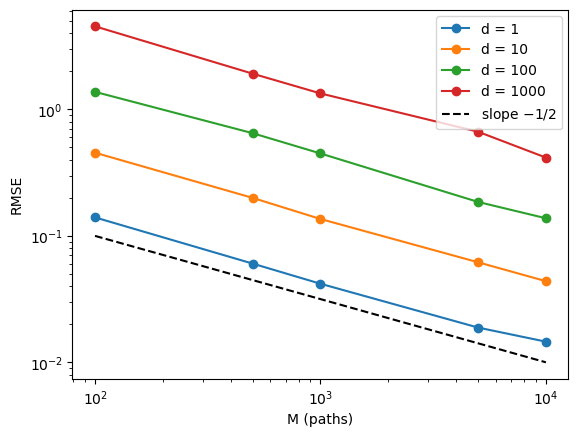

In [31]:
K = 100
Ms = np.array([100, 500, 1000, 5000, 10000])

plt.figure()
for d in [1, 10, 100, 1000]:
    xi = np.zeros(d)
    rmse = np.zeros(len(Ms))
    for i, M in enumerate(Ms):
        errs = np.zeros(K)
        for k in range(K):
            dW = rng.normal(0.0, np.sqrt(dt), size=(M, N, d))
            W = np.concatenate([np.zeros((M, 1, d)), np.cumsum(dW, axis=1)], axis=1)
            X_T = xi + W[:, -1, :]
            u_mc = g(X_T).mean()
            errs[k] = u_mc - u_exact(0, xi, d)
        rmse[i] = np.sqrt((np.sum(errs**2))/k)

    plt.loglog(Ms, rmse, 'o-', label=f'd = {d}')

    # rmse = C * M^q
    # rmse = C * M^q  =>  log(C) + q * log(M) = log(rmse)
    A = np.column_stack([np.ones(len(Ms)), np.log(Ms)])
    rhs = np.log(rmse)
    sol, *_ = np.linalg.lstsq(A, rhs, rcond=None)
    q = sol[1]
    resid = np.linalg.norm(A @ sol - rhs)
    print(f"q = {q:.4f}, resid = {resid:.4f}")

plt.loglog(Ms, 1/np.sqrt(Ms), 'k--', label=r'slope $-1/2$')
plt.xlabel('M (paths)'); plt.ylabel('RMSE'); plt.legend(); plt.show()


### Comparison with MC and a finite difference solution in $d = 1, 2$. To be continued... (show that the cost grows exponentially with d, "curse of dimensionality")
#### Limitation of MC: Monte Carlo only gives $u$ at a single point $\xi$, and it needs a known formula like Feynman–Kac, which only exists for linear PDEs.
